# Tugas - Medical Cost Prediction

| Nama | NRP |
|------|-----|
| Fauzan Tamma Harish Kunfaza | 5054251035 |

## Deskripsi Tugas

Pada tugas ini, kita akan menggunakan Medical Cost Personal Dataset dari Kaggle.

Dataset:
- https://www.kaggle.com/mirichoi0218/insurance

Target yang diprediksi adalah `charges`.

Model yang digunakan:
1. Linear Regression
2. Polynomial Regression
3. Ridge Regression
4. Lasso Regression
5. Decision Tree Regressor
6. Support Vector Regression


# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan.
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

In [ ]:
#load
df = pd.read_csv('insurance.csv')

In [ ]:
#beberapa baris pertama dataset
df.head()

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520

In [ ]:
#info dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [ ]:
#missing value
print(df.isnull().sum())
print('\nJumlah baris duplikat:', df.duplicated().sum())

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Jumlah baris duplikat: 1


In [ ]:
#tampilkan statistik deskriptif fitur numerik
df.describe()

               age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.094918  13270.422265
std      14.049960     6.098187     1.205493  12110.011237
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.296250     0.000000   4740.287150
50%      39.000000    30.400000     1.000000   9382.033000
75%      51.000000    34.693750     2.000000  16639.912515
max      64.000000    53.130000     5.000000  63770.428010

In [ ]:
#tampilkan jumlah nilai pada setiap fitur kategorikal
for col in ['sex', 'smoker', 'region']:
    print(df[col].value_counts(), '\n')

sex
male      676
female    662
Name: count, dtype: int64 

smoker
no     1064
yes     274
Name: count, dtype: int64 

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64 



## Lakukan Exploratory Data Analysis (EDA) sederhana yang diperlukan.


In [ ]:
#terdapat 1 baris duplikat jd dihapus agar tidak muncul di train sekaligus test set
df = df.drop_duplicates().reset_index(drop=True)
print('Ukuran data setelah menghapus duplikat:', df.shape)

Ukuran data setelah menghapus duplikat: (1337, 7)


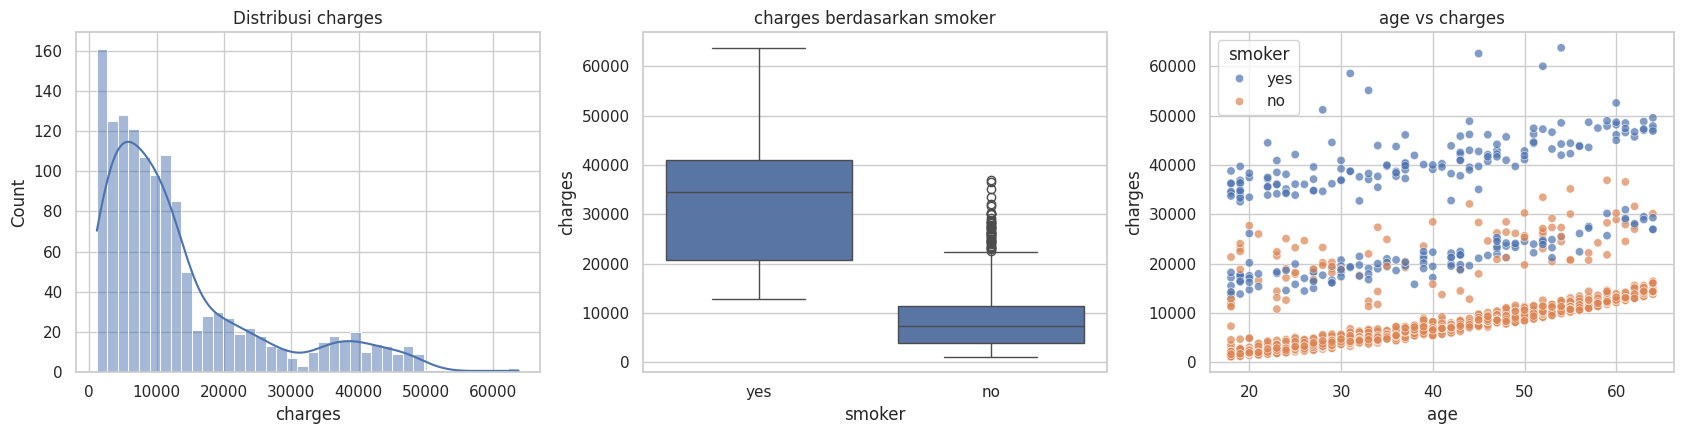

In [ ]:
#distribusi target dan hubungan charges dengan status perokok
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

sns.histplot(df['charges'], bins=40, kde=True, ax=ax[0])
ax[0].set_title('Distribusi charges')

sns.boxplot(data=df, x='smoker', y='charges', ax=ax[1])
ax[1].set_title('charges berdasarkan smoker')

sns.scatterplot(data=df, x='age', y='charges', hue='smoker', alpha=0.7, ax=ax[2])
ax[2].set_title('age vs charges')

plt.tight_layout()
plt.show()

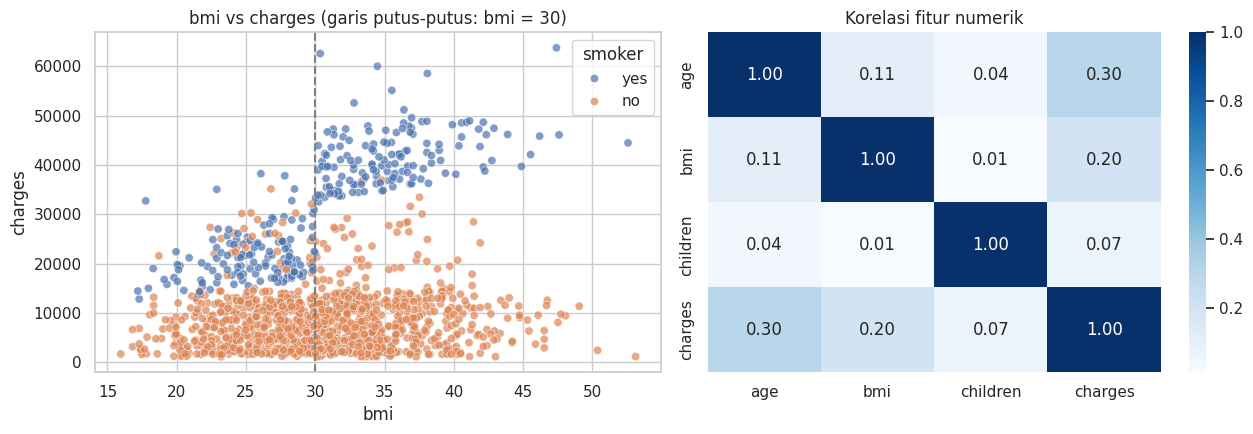

In [ ]:
#pengaruh BMI terhadap charges, dibedakan berdasarkan status perokok
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

sns.scatterplot(data=df, x='bmi', y='charges', hue='smoker', alpha=0.7, ax=ax[0])
ax[0].axvline(30, color='gray', linestyle='--')
ax[0].set_title('bmi vs charges (garis putus-putus: bmi = 30)')

sns.heatmap(df[['age', 'bmi', 'children', 'charges']].corr(), annot=True, fmt='.2f', cmap='Blues', ax=ax[1])
ax[1].set_title('Korelasi fitur numerik')

plt.tight_layout()
plt.show()

In [ ]:
#rata-rata charges berdasarkan kelompok
print(df.groupby('smoker')['charges'].mean().round(0), '\n')
print(df.groupby('region')['charges'].mean().round(0), '\n')
print(df.groupby('sex')['charges'].mean().round(0), '\n')
print(df.assign(obese=df['bmi'] >= 30).groupby(['smoker', 'obese'])['charges'].mean().round(0))

smoker
no      8441.0
yes    32050.0
Name: charges, dtype: float64 

region
northeast    13406.0
northwest    12451.0
southeast    14735.0
southwest    12347.0
Name: charges, dtype: float64 

sex
female    12570.0
male      13975.0
Name: charges, dtype: float64 

smoker  obese
no      False     7977.0
        True      8856.0
yes     False    21363.0
        True     41558.0
Name: charges, dtype: float64


**Temuan EDA:**

- Data bersih: tidak ada missing value dan hanya ada 1 baris duplikat (dihapus, sisa 1.337 baris). Dataset seimbang pada `sex` dan `region`, sedangkan `smoker` tidak seimbang (274 perokok vs 1.064 bukan perokok).
- `charges` condong ke kanan (mean ≈ 13.270, median ≈ 9.382, maksimum ≈ 63.770) dan distribusinya punya dua "gundukan", yang berkaitan dengan status perokok.
- `smoker` adalah faktor yang paling dominan: rata-rata charges perokok ≈ 32.050 vs ≈ 8.441 untuk bukan perokok.
- Pada plot `age` vs `charges`, data terbagi menjadi tiga pita yang naik seiring usia: bukan perokok (bawah), perokok dengan BMI lebih rendah (tengah), dan perokok dengan BMI tinggi (atas).
- Efek `bmi` bersifat interaksi: pada bukan perokok, BMI ≥ 30 hampir tidak mengubah charges (≈ 7.977 vs ≈ 8.856), tetapi pada perokok melonjak dari ≈ 21.363 menjadi ≈ 41.558. Hubungan seperti ini tidak dapat ditangkap model linear biasa.
- Korelasi linear numerik lemah-sedang: `age` ≈ 0,30, `bmi` ≈ 0,20, `children` ≈ 0,07. Perbedaan rata-rata antar `sex` dan `region` kecil dibandingkan `smoker`.

# 2. Preprocessing

Pisahkan fitur numerik dan kategorikal. Gunakan OneHotEncoder untuk fitur kategorikal.

Model Linear Regression, Polynomial Regression, Ridge, Lasso, dan SVR menggunakan data yang telah di-scaling. Decision Tree Regressor tidak memerlukan scaling.


In [12]:
# Pisahkan fitur (X) dan target (y).
X = df.drop(columns='charges')
y = df['charges']
print(X.shape, y.shape)

(1337, 6) (1337,)


In [13]:
# Identifikasi kolom numerik dan kategorikal.
num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()
print('Numerik    :', num_cols)
print('Kategorikal:', cat_cols)

Numerik    : ['age', 'bmi', 'children']
Kategorikal: ['sex', 'smoker', 'region']


In [14]:
# Bagi data menjadi train set dan test set.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (1069, 6) | Test: (268, 6)


In [ ]:
# Buat preprocessing untuk fitur numerik dan kategorikal.

# untuk Linear, Polynomial, Ridge, Lasso, dan SVR:
#     fitur numerik di-scaling (StandardScaler), fitur kategorikal di-one-hot encode
preprocessor_scaled = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols),
])

# untuk Decision Tree: fitur numerik dibiarkan apa adanya (tanpa scaling),
#     fitur kategorikal tetap di-one-hot encode
preprocessor_tree = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols),
])

#cek hasil transformasi (fit hanya pada train set agar tidak terjadi data leakage)
Xt = preprocessor_scaled.fit_transform(X_train)
feature_names = preprocessor_scaled.get_feature_names_out()
print('Bentuk data hasil preprocessing:', Xt.shape)
pd.DataFrame(Xt, columns=feature_names).head()

Bentuk data hasil preprocessing: (1069, 8)


   num__age  num__bmi  ...  cat__region_southeast  cat__region_southwest
0 -1.157680 -0.996928  ...                    0.0                    0.0
1 -1.300619 -0.792762  ...                    0.0                    0.0
2  0.914926  1.154664  ...                    0.0                    0.0
3  1.701087  1.806837  ...                    1.0                    0.0
4  0.557580 -0.651417  ...                    0.0                    0.0

[5 rows x 8 columns]

Preprocessing dimasukkan ke dalam `Pipeline` bersama model. Dengan begitu, scaler dan encoder hanya di-fit pada data latih (termasuk pada setiap fold cross-validation), sehingga tidak ada kebocoran informasi dari data validasi atau test set.

Untuk memilih parameter (`degree`, `alpha`, `max_depth`, dst.) digunakan `GridSearchCV` dengan 5-fold cross-validation **pada train set saja**. Test set hanya dipakai satu kali untuk evaluasi akhir.

In [ ]:
#skema cross-validation dan metrik yang dipakai untuk memilih parameter
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = 'neg_root_mean_squared_error'

def cv_table(grid, param_cols):
    """Ringkas hasil GridSearchCV menjadi tabel (RMSE train & validasi)."""
    res = pd.DataFrame(grid.cv_results_)
    out = res[param_cols].copy()
    out.columns = [c.split('__')[-1] for c in param_cols]
    out['RMSE train'] = (-res['mean_train_score']).round(2)
    out['RMSE validasi'] = (-res['mean_test_score']).round(2)
    return out

# 3. Eksperimen Model

## 3.1 Linear Regression

Bangun model Linear Regression menggunakan data hasil preprocessing.


In [17]:
# Inisialisasi dan latih Linear Regression.
lin_reg = Pipeline([
    ('prep', preprocessor_scaled),
    ('model', LinearRegression()),
])
lin_reg.fit(X_train, y_train)

coef = pd.Series(lin_reg.named_steps['model'].coef_, index=feature_names)
print('Intercept:', round(lin_reg.named_steps['model'].intercept_, 2))
coef.sort_values(key=abs, ascending=False).round(2)

Intercept: 8947.95


cat__smoker_yes          23077.76
num__age                  3472.98
num__bmi                  1927.83
cat__region_southeast     -838.92
cat__region_southwest     -659.14
num__children              636.50
cat__region_northwest     -391.76
cat__sex_male             -101.54
dtype: float64

In [18]:
# Lakukan prediksi pada test set.
y_pred_lin = lin_reg.predict(X_test)
y_pred_lin[:5].round(2)

array([ 8143.69,  5737.12, 14369.31, 31745.51,  8962.39])

## 3.2 Polynomial Regression

Gunakan PolynomialFeatures. Tentukan degree berdasarkan eksperimen.


In [19]:
# Buat fitur polynomial dan latih model.
poly_pipe = Pipeline([
    ('prep', preprocessor_scaled),
    ('poly', PolynomialFeatures(include_bias=False)),
    ('model', LinearRegression()),
])
poly_grid = GridSearchCV(
    poly_pipe, {'poly__degree': [1, 2, 3, 4]},
    cv=cv, scoring=scoring, return_train_score=True,
)
poly_grid.fit(X_train, y_train)

print('Degree terbaik:', poly_grid.best_params_['poly__degree'])
cv_table(poly_grid, ['param_poly__degree'])

Degree terbaik: 2


   degree  RMSE train  RMSE validasi
0       1     6075.92        6123.65
1       2     4748.62        4931.59
2       3     4514.11        5169.48
3       4     4117.74        6692.36

In [20]:
# Lakukan prediksi pada test set.
poly_reg = poly_grid.best_estimator_
y_pred_poly = poly_reg.predict(X_test)
y_pred_poly[:5].round(2)

array([ 8353.84,  6542.12, 14316.74, 35908.93,  5652.8 ])

## 3.3 Ridge Regression

Gunakan Ridge Regression. Tentukan nilai alpha berdasarkan eksperimen.


In [21]:
# Inisialisasi dan latih Ridge Regression.
ridge_pipe = Pipeline([
    ('prep', preprocessor_scaled),
    ('model', Ridge(random_state=RANDOM_STATE)),
])
ridge_grid = GridSearchCV(
    ridge_pipe, {'model__alpha': [0.001, 0.01, 0.1, 1, 10, 100, 1000]},
    cv=cv, scoring=scoring, return_train_score=True,
)
ridge_grid.fit(X_train, y_train)

print('Alpha terbaik:', ridge_grid.best_params_['model__alpha'])
cv_table(ridge_grid, ['param_model__alpha'])

Alpha terbaik: 0.1


      alpha  RMSE train  RMSE validasi
0     0.001     6075.92        6123.65
1     0.010     6075.92        6123.65
2     0.100     6075.92        6123.64
3     1.000     6076.30        6123.91
4    10.000     6109.46        6156.15
5   100.000     7235.77        7280.08
6  1000.000    10320.49       10340.96

In [22]:
# Lakukan prediksi pada test set.
ridge_reg = ridge_grid.best_estimator_
y_pred_ridge = ridge_reg.predict(X_test)
y_pred_ridge[:5].round(2)

array([ 8146.4 ,  5740.2 , 14370.39, 31734.61,  8966.53])

## 3.4 Lasso Regression

Gunakan Lasso Regression. Tentukan nilai alpha berdasarkan eksperimen.


In [23]:
# Inisialisasi dan latih Lasso Regression.
lasso_pipe = Pipeline([
    ('prep', preprocessor_scaled),
    ('model', Lasso(max_iter=20000, random_state=RANDOM_STATE)),
])
lasso_grid = GridSearchCV(
    lasso_pipe, {'model__alpha': [0.01, 0.1, 1, 10, 100, 1000]},
    cv=cv, scoring=scoring, return_train_score=True,
)
lasso_grid.fit(X_train, y_train)

print('Alpha terbaik:', lasso_grid.best_params_['model__alpha'])
cv_table(lasso_grid, ['param_model__alpha'])

Alpha terbaik: 100


     alpha  RMSE train  RMSE validasi
0     0.01     6075.92        6123.65
1     0.10     6075.92        6123.63
2     1.00     6075.92        6123.43
3    10.00     6076.41        6121.87
4   100.00     6093.08        6121.41
5  1000.00     6765.31        6793.18

In [24]:
# Lakukan prediksi pada test set.
lasso_reg = lasso_grid.best_estimator_
y_pred_lasso = lasso_reg.predict(X_test)

lasso_coef = pd.Series(lasso_reg.named_steps['model'].coef_, index=feature_names)
print('Koefisien yang menjadi nol:', list(lasso_coef[lasso_coef == 0].index))
y_pred_lasso[:5].round(2)

Koefisien yang menjadi nol: ['cat__sex_male', 'cat__region_northwest', 'cat__region_southeast', 'cat__region_southwest']


array([ 8094.11,  5988.23, 13986.67, 30966.14,  9254.67])

## 3.5 Decision Tree Regressor

Gunakan Decision Tree Regressor. Eksperimen dapat dilakukan pada `max_depth` dan `min_samples_leaf`.


In [25]:
# Inisialisasi dan latih Decision Tree Regressor.
tree_pipe = Pipeline([
    ('prep', preprocessor_tree),
    ('model', DecisionTreeRegressor(random_state=RANDOM_STATE)),
])
tree_grid = GridSearchCV(
    tree_pipe,
    {'model__max_depth': [2, 3, 4, 5, 6, 8, 10, None],
     'model__min_samples_leaf': [1, 5, 10, 20, 30]},
    cv=cv, scoring=scoring, return_train_score=True,
)
tree_grid.fit(X_train, y_train)

print('Parameter terbaik:', tree_grid.best_params_)
tree_tbl = cv_table(tree_grid, ['param_model__max_depth', 'param_model__min_samples_leaf'])
tree_tbl.sort_values('RMSE validasi').head(8)

Parameter terbaik: {'model__max_depth': 4, 'model__min_samples_leaf': 5}


   max_depth  min_samples_leaf  RMSE train  RMSE validasi
11         4                 5     4399.21        4718.59
17         5                10     4267.79        4722.70
12         4                10     4400.37        4725.60
18         5                20     4351.53        4741.38
13         4                20     4436.23        4744.45
16         5                 5     4238.67        4757.04
15         5                 1     4208.61        4771.79
10         4                 1     4381.68        4773.60

In [26]:
# Lakukan prediksi pada test set.
tree_reg = tree_grid.best_estimator_
y_pred_tree = tree_reg.predict(X_test)

imp = pd.Series(tree_reg.named_steps['model'].feature_importances_,
                index=tree_reg.named_steps['prep'].get_feature_names_out())
print('Feature importance:')
print(imp.sort_values(ascending=False).round(3).head(5))
y_pred_tree[:5].round(2)

Feature importance:
cat__smoker_yes    0.701
num__bmi           0.172
num__age           0.119
num__children      0.008
cat__sex_male      0.000
dtype: float64


array([11016.04,  7357.27, 11016.04, 40778.86,  7357.27])

## 3.6 Support Vector Regression

Gunakan SVR dengan data yang telah di-scaling. Tentukan parameter berdasarkan eksperimen.


In [ ]:
# Inisialisasi dan latih SVR.
#target `charges` berskala puluhan ribu, sehingga C dan epsilon perlu dicari pada rentang besar
svr_pipe = Pipeline([
    ('prep', preprocessor_scaled),
    ('model', SVR(kernel='rbf')),
])
svr_grid = GridSearchCV(
    svr_pipe,
    {'model__C': [1e4, 1e5],
     'model__gamma': [0.03, 0.1],
     'model__epsilon': [10, 1000]},
    cv=cv, scoring=scoring, return_train_score=True, n_jobs=-1,
)
svr_grid.fit(X_train, y_train)

print('Parameter terbaik:', svr_grid.best_params_)
cv_table(svr_grid, ['param_model__C', 'param_model__gamma', 'param_model__epsilon']).sort_values('RMSE validasi')

Parameter terbaik: {'model__C': 100000.0, 'model__epsilon': 1000, 'model__gamma': 0.03}


          C  gamma  epsilon  RMSE train  RMSE validasi
6  100000.0   0.03     1000     4781.12        4854.08
7  100000.0   0.10     1000     4616.63        4938.13
4  100000.0   0.03       10     4952.17        4992.11
3   10000.0   0.10     1000     4857.38        5000.08
5  100000.0   0.10       10     4838.53        5028.58
1   10000.0   0.10       10     5023.33        5109.70
2   10000.0   0.03     1000     6377.50        6420.81
0   10000.0   0.03       10     6693.23        6717.62

In [28]:
# Lakukan prediksi pada test set.
svr_reg = svr_grid.best_estimator_
y_pred_svr = svr_reg.predict(X_test)
y_pred_svr[:5].round(2)

array([ 9482.98,  6519.41, 12528.61, 34132.75,  5285.6 ])

In [ ]:
#eksperimen tambahan (tidak masuk tabel perbandingan):
#jika target ikut discaling, SVR dapat bekerja dengan C dan epsilon berskala kecil
svr_ty = Pipeline([
    ('prep', preprocessor_scaled),
    ('model', TransformedTargetRegressor(regressor=SVR(kernel='rbf'), transformer=StandardScaler())),
])
svr_ty_grid = GridSearchCV(
    svr_ty,
    {'model__regressor__C': [1, 10, 100],
     'model__regressor__gamma': [0.03, 0.1],
     'model__regressor__epsilon': [0.1, 0.3]},
    cv=cv, scoring=scoring, n_jobs=-1,
)
svr_ty_grid.fit(X_train, y_train)
p = svr_ty_grid.predict(X_test)
print('Parameter terbaik:', svr_ty_grid.best_params_)
print('Test RMSE:', round(np.sqrt(mean_squared_error(y_test, p)), 2), '| R2:', round(r2_score(y_test, p), 4))

Parameter terbaik: {'model__regressor__C': 10, 'model__regressor__epsilon': 0.1, 'model__regressor__gamma': 0.03}
Test RMSE: 4575.34 | R2: 0.8861


# 4. Evaluasi Model

In [30]:
# Hitung MAE, MSE, RMSE, dan R² untuk setiap model.
# Sajikan hasil dalam satu tabel perbandingan.
models = {
    'Linear Regression':        lin_reg,
    'Polynomial Regression':    poly_reg,
    'Ridge Regression':         ridge_reg,
    'Lasso Regression':         lasso_reg,
    'Decision Tree Regressor':  tree_reg,
    'Support Vector Regression': svr_reg,
}
preds = {
    'Linear Regression':        y_pred_lin,
    'Polynomial Regression':    y_pred_poly,
    'Ridge Regression':         y_pred_ridge,
    'Lasso Regression':         y_pred_lasso,
    'Decision Tree Regressor':  y_pred_tree,
    'Support Vector Regression': y_pred_svr,
}

rows = []
for name, y_pred in preds.items():
    mse = mean_squared_error(y_test, y_pred)
    rows.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, y_pred),
        'MSE': mse,
        'RMSE': np.sqrt(mse),
        'R² Test': r2_score(y_test, y_pred),
        'R² Train': r2_score(y_train, models[name].predict(X_train)),
    })

results = pd.DataFrame(rows).set_index('Model').sort_values('RMSE')
results.round(4)

                                 MAE           MSE  ...  R² Test  R² Train
Model                                               ...                   
Decision Tree Regressor    2621.3124  1.888663e+07  ...   0.8972    0.8552
Support Vector Regression  2378.1680  2.101929e+07  ...   0.8856    0.8330
Polynomial Regression      2867.3174  2.158584e+07  ...   0.8825    0.8340
Linear Regression          4177.0456  3.547802e+07  ...   0.8069    0.7299
Ridge Regression           4178.7395  3.549633e+07  ...   0.8068    0.7299
Lasso Regression           4256.5831  3.696435e+07  ...   0.7988    0.7286

[6 rows x 5 columns]

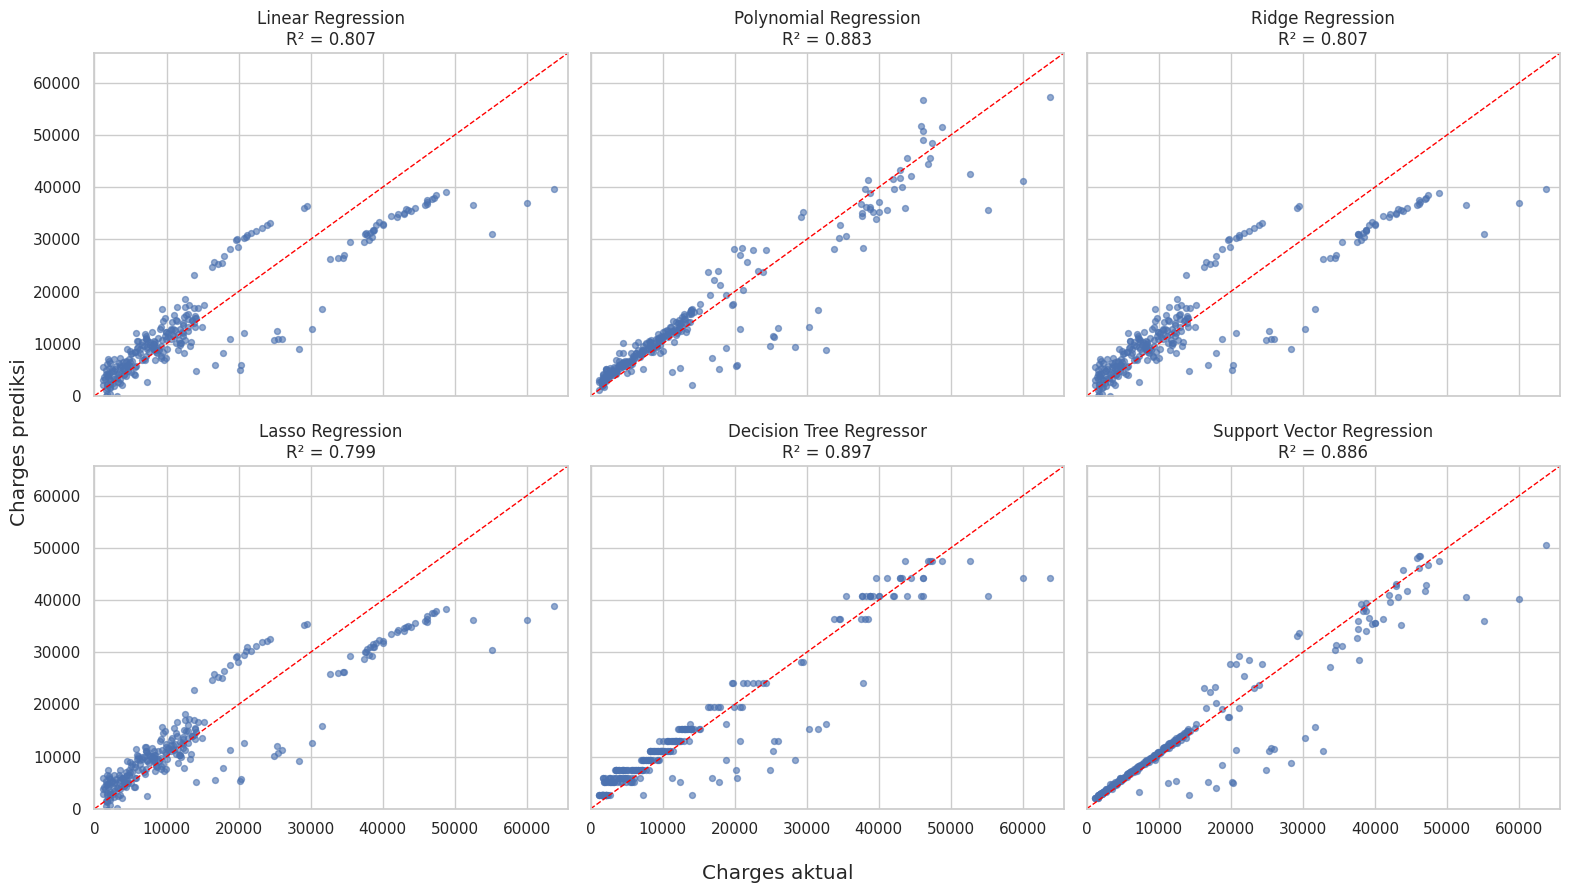

In [31]:
# Buat visualisasi perbandingan nilai aktual dan prediksi jika diperlukan.
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True, sharey=True)
lim = [0, max(y_test.max(), max(p.max() for p in preds.values())) * 1.03]

for ax, (name, y_pred) in zip(axes.ravel(), preds.items()):
    ax.scatter(y_test, y_pred, s=18, alpha=0.6)
    ax.plot(lim, lim, color='red', linestyle='--', linewidth=1)
    ax.set_title(f"{name}\nR² = {r2_score(y_test, y_pred):.3f}")
    ax.set_xlim(lim); ax.set_ylim(lim)

fig.supxlabel('Charges aktual')
fig.supylabel('Charges prediksi')
plt.tight_layout()
plt.show()

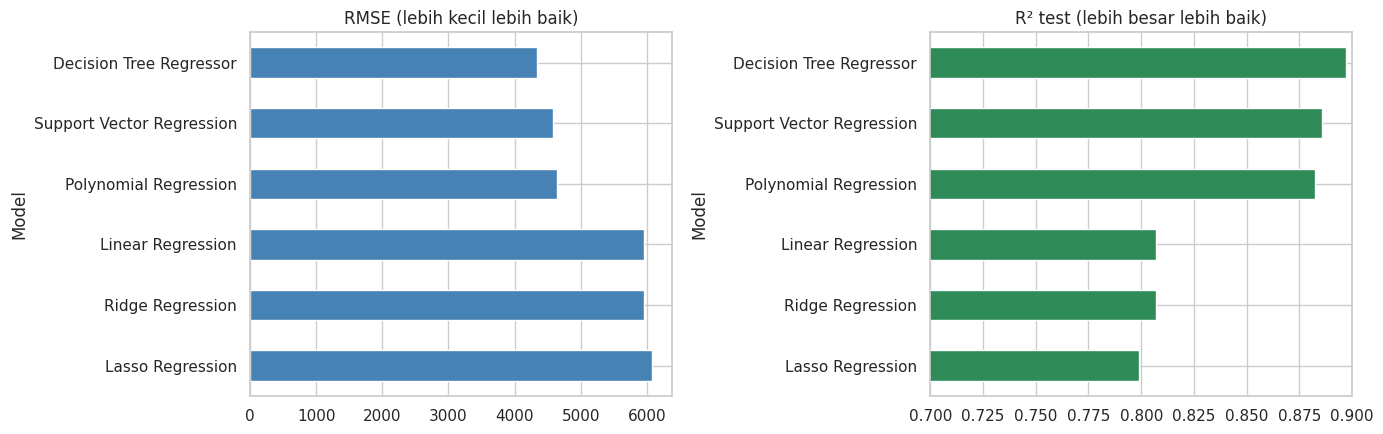

In [32]:
# Perbandingan RMSE dan R² antar model.
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
results['RMSE'].sort_values(ascending=False).plot.barh(ax=ax[0], color='steelblue')
ax[0].set_title('RMSE (lebih kecil lebih baik)')
results['R² Test'].sort_values().plot.barh(ax=ax[1], color='seagreen')
ax[1].set_title('R² test (lebih besar lebih baik)')
ax[1].set_xlim(0.7, 0.9)
plt.tight_layout()
plt.show()

# 5. Analisis

#### Bandingkan hasil Linear Regression, Polynomial Regression, Ridge, Lasso, Decision Tree Regressor, dan SVR berdasarkan metrik evaluasi. Jelaskan pengaruh preprocessing dan parameter yang digunakan terhadap hasil.

**1. Perbandingan metrik (test set, diurutkan dari RMSE terkecil)**

| Model | MAE | RMSE | R² Test |
|---|---|---|---|
| Decision Tree Regressor (`max_depth=4`, `min_samples_leaf=5`) | 2.621 | 4.346 | 0,897 |
| Support Vector Regression (RBF, `C=1e5`, `gamma=0.03`, `epsilon=1000`) | 2.378 | 4.585 | 0,886 |
| Polynomial Regression (`degree=2`) | 2.867 | 4.646 | 0,883 |
| Linear Regression | 4.177 | 5.956 | 0,807 |
| Ridge Regression (`alpha=0.1`) | 4.179 | 5.958 | 0,807 |
| Lasso Regression (`alpha=100`) | 4.257 | 6.080 | 0,799 |

Model terbagi jelas menjadi dua kelompok. Kelompok **non-linear/berinteraksi** (Decision Tree, SVR, Polynomial) mencapai R² ≈ 0,88–0,90 dan RMSE ≈ 4.300–4.650. Kelompok **linear murni** (Linear, Ridge, Lasso) berhenti di R² ≈ 0,80–0,81 dengan RMSE ≈ 6.000, atau sekitar 30% lebih besar. Selisih dalam kelompok kedua sangat kecil, sedangkan selisih antar kelompok besar.

**2. Mengapa model non-linear lebih baik**

Sesuai EDA, hubungan `charges` dengan fitur bukan sekadar penjumlahan: efek `bmi` dan `age` bergantung pada `smoker`. Linear Regression memaksa satu kemiringan yang sama untuk semua kelompok sehingga sistematis meleset (pada plot aktual vs prediksi terlihat prediksi untuk perokok ber-BMI tinggi terlalu rendah dan untuk bukan perokok terlalu tinggi). Polynomial degree 2 menambahkan suku interaksi (misalnya `smoker × bmi`) dan kuadrat, sehingga RMSE turun dari 5.956 menjadi 4.646. Decision Tree menangkap interaksi secara alami lewat pemisahan bertingkat, dan feature importance-nya konsisten dengan EDA: `smoker` ≈ 0,70, `bmi` ≈ 0,17, `age` ≈ 0,12, sedangkan `children` hanya ≈ 0,01 dan `sex`/`region` praktis tidak dipakai. SVR dengan kernel RBF juga dapat membentuk permukaan non-linear.

**3. Pengaruh parameter (berdasarkan 5-fold CV pada train set)**

- **Polynomial:** RMSE validasi degree 1 → 4 adalah 6.124 → 4.932 → 5.169 → 6.692, sementara RMSE train terus turun (6.076 → 4.749 → 4.514 → 4.118). Degree 2 optimal. Degree 3–4 mulai *overfitting*, terlihat dari jarak train–validasi yang melebar.
- **Ridge:** pada `alpha` ≤ 1 hasil praktis identik dengan Linear Regression (RMSE validasi ≈ 6.124), lalu memburuk saat `alpha` besar (7.280 pada 100 dan 10.341 pada 1000) karena koefisien ditekan hingga *underfitting*. Hanya ada 8 fitur dan 1.069 sampel, jadi model linear tidak overfit dan regularisasi tidak memberi keuntungan.
- **Lasso:** `alpha=100` sedikit menurunkan RMSE validasi (6.121 vs 6.124, selisih tidak berarti) dan membuat koefisien `sex` dan ketiga dummy `region` menjadi nol, selaras dengan temuan EDA bahwa fitur-fitur itu lemah. Namun pada test set Lasso sedikit lebih buruk daripada Linear (RMSE 6.080 vs 5.956). Pada `alpha=1000` model mulai underfitting (6.793).
- **Decision Tree:** kombinasi terbaik adalah `max_depth=4`, `min_samples_leaf=5` (RMSE validasi 4.719). Pohon tanpa batasan kedalaman akan menghafal data latih, sedangkan `max_depth` terlalu kecil membuat pohon terlalu sederhana. `min_samples_leaf` membantu menstabilkan prediksi pada daun yang berisi sedikit sampel.
- **SVR:** karena `charges` berskala puluhan ribu, `C` kecil membuat model underfit. `C=1e4` dengan `gamma=0.03` hanya menghasilkan RMSE validasi ≈ 6.400–6.700, sedangkan `C=1e5` menurunkannya menjadi ≈ 4.850. Nilai `epsilon` yang besar (1000, sekitar 8% dari rata-rata charges) membantu mengabaikan *noise* kecil. SVR peka terhadap kombinasi `C`, `gamma`, dan `epsilon`.

**4. Pengaruh preprocessing**

- **Scaling:** `StandardScaler` pada fitur numerik penting untuk SVR (berbasis jarak/kernel) dan untuk Ridge/Lasso (penalti dikenakan sama rata pada setiap koefisien, sehingga skala fitur memengaruhi seberapa besar suatu fitur dipenalti). Untuk Linear/Polynomial Regression scaling tidak mengubah prediksi, tetapi membuat koefisien dapat dibandingkan dan komputasi polynomial lebih stabil. Decision Tree tidak memerlukan scaling karena hanya memakai urutan nilai fitur.
- **OneHotEncoder (`drop='first'`):** mengubah `sex`, `smoker`, dan `region` menjadi fitur biner sehingga dapat dipakai model numerik. `drop='first'` menghindari multikolinearitas sempurna pada model linear.
- **Pipeline:** scaler dan encoder di-fit hanya pada data latih (termasuk di setiap fold CV), sehingga hasil evaluasi tidak bocor dari data validasi/test.
- **Eksperimen tambahan:** jika target `charges` ikut di-scaling (`TransformedTargetRegressor`), SVR dengan parameter berskala kecil (`C=10`, `gamma=0.03`, `epsilon=0.1`) memberi hasil hampir sama (RMSE 4.575, R² 0,886), jadi skala target memang menjadi alasan `C` yang optimal pada SVR sebelumnya sangat besar.

**5. Catatan kehati-hatian**

- Hasil test dari satu kali pembagian data. Perbedaan kecil antar Decision Tree, SVR, dan Polynomial (RMSE 4.346–4.646) belum tentu konsisten bila data dibagi ulang, sehingga ketiganya sebaiknya dianggap setara dibanding Linear/Ridge/Lasso. Pada CV (train set), urutan terbaiknya Decision Tree (4.719), SVR (4.854), lalu Polynomial (4.932), urutan yang sama dengan test set.
- R² train Linear (0,730) lebih rendah daripada R² test (0,807), artinya sampel test kebetulan lebih "mudah" bagi model linear. Ini wajar dan bukan tanda kebocoran data.
- MAE SVR (2.378) justru yang terkecil, walaupun RMSE-nya lebih besar daripada Decision Tree. Artinya SVR lebih akurat pada kasus umum tetapi memiliki beberapa galat besar pada kasus ekstrem (misalnya perokok dengan charges sangat tinggi), yang dipenalti kuat oleh RMSE.

# 6. Kesimpulan dan Saran

#### Berikan kesimpulan berdasarkan hasil eksperimen. Saran dapat berupa perubahan parameter, preprocessing, atau eksperimen lanjutan.

**Kesimpulan**

1. Pada dataset ini Decision Tree Regressor memberi hasil terbaik berdasarkan RMSE dan R² (RMSE ≈ 4.346, R² ≈ 0,897), diikuti SVR (RMSE ≈ 4.585, R² ≈ 0,886) dan Polynomial Regression degree 2 (RMSE ≈ 4.646, R² ≈ 0,883). Berdasarkan MAE, SVR terbaik (≈ 2.378). Selisih ketiganya kecil, sedangkan ketiganya jelas lebih baik daripada Linear, Ridge, dan Lasso (RMSE ≈ 5.956–6.080, R² ≈ 0,80–0,81).
2. Keunggulan model non-linear berasal dari kemampuannya menangkap interaksi `smoker` × `bmi` dan `smoker` × `age`. Faktor penentu biaya medis yang paling kuat adalah status perokok, kemudian BMI dan usia; jumlah anak berpengaruh kecil, sedangkan jenis kelamin dan wilayah hampir tidak berpengaruh (Lasso menolnya, Decision Tree tidak memakainya).
3. Regularisasi (Ridge/Lasso) tidak memperbaiki model linear karena masalahnya adalah *underfitting* (model terlalu sederhana), bukan *overfitting*.
4. Pemilihan parameter lewat cross-validation penting: degree polynomial > 2 mulai overfit, `max_depth` pohon perlu dibatasi (4), dan SVR membutuhkan `C` besar karena skala target. Preprocessing (scaling untuk model berbasis jarak/regularisasi, one-hot untuk fitur kategorikal, pipeline tanpa kebocoran data) memastikan perbandingan model adil.

**Saran**

- Tambahkan fitur turunan secara eksplisit, misalnya `bmi ≥ 30` (obesitas), `smoker × bmi`, atau `smoker × age`. Fitur ini dapat meningkatkan Linear/Ridge/Lasso mendekati model non-linear tanpa kehilangan interpretabilitas.
- Coba model ensemble berbasis pohon (Random Forest, Gradient Boosting) yang biasanya lebih stabil daripada satu pohon tunggal, serta periksa transformasi log pada `charges` untuk mengurangi kemiringan distribusi target.
- Gunakan cross-validation berulang (atau beberapa `random_state`) pada tahap evaluasi akhir agar perbandingan model yang selisihnya kecil lebih meyakinkan, dan perluas grid parameter (misalnya `degree` + Ridge pada Polynomial, atau `gamma` dan `epsilon` pada SVR) bila waktu komputasi memungkinkan.
- Pada SVR, scaling target dapat dicoba agar rentang parameter lebih kecil dan pencarian lebih cepat.